# Исследование рынка общественного питания Москвы

## Введение

В этом проекте мы изучим рынок общественного питания Москвы. Цель исследования — выяснить, какие заведения работают в городе, как они распределяются по округам, чем отличаются по ценам, рейтингам и количеству посадочных мест.

На основе полученных результатов попробуем определить, какие категории заведений и районы Москвы можно рассмотреть для открытия нового бизнеса.

**Для этого нам предстоит:**

1. Загрузить данные о заведениях и ценах, изучить их структуру.
2. Провести предобработку данных: проверить пропуски, дубликаты и типы данных.
3. Изучить распределение заведений по категориям и административным округам Москвы.
4. Сравнить сетевые и несетевые заведения, количество посадочных мест, рейтинги и цены.
5. Сделать общие выводы и подготовить рекомендации для инвесторов.

Для исследования будем использовать два датасета: один содержит основную информацию о заведениях, второй — информацию о ценах. После объединения таблиц проведём исследовательский анализ данных с помощью Python и библиотек pandas, matplotlib и seaborn.

## Шаг 1. Загрузка и изучение данных

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import phik

In [2]:
try:
    df_info = pd.read_csv('/datasets/rest_info.csv')
    df_price = pd.read_csv('/datasets/rest_price.csv')
except FileNotFoundError:
    df_info = pd.read_csv('rest_info.csv')
    df_price = pd.read_csv('rest_price.csv')

In [3]:
df_info.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


In [4]:
display(df_info[:5])

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [5]:
df_price.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


In [6]:
display(df_price[:5])

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


In [7]:
print(df_info['id'].duplicated().sum())
print(df_price['id'].duplicated().sum())

0
0


In [8]:
df = df_info.merge(df_price, how='left', on='id')
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), object(8)
memory usage: 919.4+ KB


In [9]:
display(df.describe())

display(df.describe(include='object'))

display(df.nunique())

,rating,chain,seats,middle_avg_bill,middle_coffee_cup
count,8406.000000,8406.000000,4795.000000,3149.000000,535.000000
mean,4.229895,0.381275,108.421689,958.053668,174.721495
std,0.470348,0.485729,122.833396,1009.732845,88.951103
min,1.000000,0.000000,0.000000,0.000000,60.000000
25%,4.100000,0.000000,40.000000,375.000000,124.500000
50%,4.300000,0.000000,75.000000,750.000000,169.000000
75%,4.400000,1.000000,140.000000,1250.000000,225.000000
max,5.000000,1.000000,1288.000000,35000.000000,1568.000000


,id,name,category,address,district,hours,price,avg_bill
count,8406,8406,8406,8406,8406,7870,3315,3816
unique,8406,5614,8,5753,9,1307,4,897
top,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,Кафе,кафе,"Москва, проспект Вернадского, 86В",Центральный административный округ,"ежедневно, 10:00–22:00",средние,Средний счёт:1000–1500 ₽
freq,1,189,2378,28,2242,759,2117,241


id                   8406
name                 5614
category                8
address              5753
district                9
hours                1307
rating                 41
chain                   2
seats                 229
price                   4
avg_bill              897
middle_avg_bill       230
middle_coffee_cup      96
dtype: int64

**Промежуточный вывод**

1. Загружены две таблицы. В таблице с информацией о заведениях (`rest_info`) 8406 строк. В таблице с ценами (`rest_price`) 4058 строк. 
2. Таблицы объединены в один датафрейм методом `LEFT JOIN` по ключу `id`. Выбран левый джойн, чтобы сохранить в анализе все 8406 заведений, даже если информация о ценах для них отсутствует.
3. Обнаружено большое количество пропусков. В данных о посадке (`seats`) заполнено только около половины значений. Также много пропусков в данных о ценах (`price`, `avg_bill`), а цена чашки кофе известна лишь для 535 заведений из 8406.

## Шаг 2. Предобработка данных

In [10]:
for column in df.columns:
    print(f"=== Колонка: {column} ===")
    print(f"Тип данных (pandas): {df[column].dtype}")
    print("Топ-15 частых значений:")
    # value_counts() считает частоту, head(15) берет первые 15
    print(df[column].value_counts().head(15))
    print("\n" + "="*40 + "\n")

=== Колонка: id ===
Тип данных (pandas): object
Топ-15 частых значений:
0c3e3439a8c64ea5bf6ecd6ca6ae19f0    1
644e884f8c6c49e3a8cb86dd2e3fd323    1
ca26cd67a4a343eb89a928b34b0092f1    1
402ee2415f264b588cf1156c18542996    1
a0ef4263f4a64b6fbeed6b3520a43c42    1
0b77b90a58524e82aab529317f1506a5    1
6c61c2a62e794f468de703ce272812c0    1
a1545bb083684e1e876f95b5358aff6a    1
76743b6ab8064a8bb829a2fbcde6e7c1    1
3cc3d54002534372afd693fe7fa2641e    1
2f31bbfc227d437fb94abe5538c12841    1
07c92ba7f0744891ab41fcfa691a4f00    1
1a9e651036ea4a9f80e120d513cf9b40    1
2afba76ed21d4b518a04c5dc2dec6bb1    1
dd3004a777274c81b26463baa63f1653    1
Name: id, dtype: int64


=== Колонка: name ===
Тип данных (pandas): object
Топ-15 частых значений:
Кафе                                   189
Шоколадница                            120
Домино'с Пицца                          76
Додо Пицца                              74
One Price Coffee                        71
Яндекс Лавка                            69
C

In [11]:
df.isna().sum()

id                      0
name                    0
category                0
address                 0
district                0
hours                 536
rating                  0
chain                   0
seats                3611
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
dtype: int64

In [12]:
df['seats'] = df['seats'].astype('Int64')

**Промежуточный вывод**

1. Гипотеза: Пропуски возникли из-за неполного заполнения карточек заведений владельцами или сбоев алгоритмов Яндекса при сборе данных.

2. Пропуски оставлены как есть (NaN), чтобы не искажать статистику (нули применять нельзя, так как это изменит суть бизнес-модели, а удаление строк приведет к потере 60% данных).

3. Столбец `seats` переведен в целочисленный тип Int64, устойчивый к пропускам.

In [13]:
df['hours'] = df['hours'].fillna('Нет информации')
df['price'] = df['price'].fillna('Нет информации')
df['avg_bill'] = df['avg_bill'].fillna('Нет информации')

In [14]:
df.duplicated().sum()

0

In [15]:
df['name'] = df['name'].str.lower().str.strip()
df['address'] = df['address'].str.lower().str.strip()

In [16]:
df.duplicated(subset=['name', 'address']).sum()

4

In [17]:
df['name'] = df['name'].str.replace("'", "", regex=False)

df['address'] = df['address'].str.replace('^москва, ', '', regex=True)

duplicates = df.duplicated(subset=['name', 'address']).sum()
print(f'Найдено и удалено дубликатов: {duplicates}')
df = df.drop_duplicates(subset=['name', 'address']).reset_index(drop=True)

Найдено и удалено дубликатов: 4


In [18]:
# Проверяем подозрительные значения количества мест
suspect_seats = df[df['seats'] == 1288]

print('Количество заведений с 1288 местами:', len(suspect_seats))

display(
    suspect_seats[
        ['name', 'category', 'seats', 'address']
    ]
)

Количество заведений с 1288 местами: 11


,name,category,seats,address
6514,delonixcafe,ресторан,1288,"проспект вернадского, 94, корп. 1"
6520,ян примус,ресторан,1288,"проспект вернадского, 121, корп. 1"
6570,мюнгер,пиццерия,1288,"проспект вернадского, 97, корп. 1"
6637,one price coffee,кофейня,1288,"проспект вернадского, 84, стр. 1"
6654,гудбар,"бар,паб",1288,"проспект вернадского, 97, корп. 1"
6680,пивной ресторан,"бар,паб",1288,"проспект вернадского, 121, корп. 1"
6686,японская кухня,ресторан,1288,"проспект вернадского, 121, корп. 1"
6767,точка,кафе,1288,"проспект вернадского, 84, стр. 1"
6803,loft-cafe академия,кафе,1288,"проспект вернадского, 84, стр. 1"
6804,яндекс лавка,ресторан,1288,"проспект вернадского, 51, стр. 1"


In [19]:
# Находим подозрительные значения на проспекте Вернадского
mask = (
    (df['seats'] == 1288) &
    (df['address'].str.contains(
        'проспект вернадского', na=False
    ))
)

print('Количество исправленных значений:', mask.sum())

# Заменяем значения на пропуски
df.loc[mask, 'seats'] = pd.NA

print(df['seats'].describe())

Количество исправленных значений: 11
count    4781.000000
mean      105.647354
std       109.155834
min         0.000000
25%        40.000000
50%        75.000000
75%       135.000000
max      1200.000000
Name: seats, dtype: float64


In [20]:
# Проверяем, остались ли заведения с 1288 местами
display(
    df.loc[
        df['seats'] == 1288,
        ['name', 'category', 'seats', 'address']
    ]
)

,name,category,seats,address


In [21]:
df['is_24_7'] = (
    df['hours'].str.contains('круглосуточно', na=False) & 
    df['hours'].str.contains('ежедневно', na=False)
)

In [22]:
df['is_24_7'].value_counts()

False    7672
True      730
Name: is_24_7, dtype: int64

In [23]:
# Создаем словарь с сокращенными названиями округов
district_names = {
    'Центральный административный округ': 'ЦАО',
    'Северный административный округ': 'САО',
    'Северо-Восточный административный округ': 'СВАО',
    'Восточный административный округ': 'ВАО',
    'Юго-Восточный административный округ': 'ЮВАО',
    'Южный административный округ': 'ЮАО',
    'Юго-Западный административный округ': 'ЮЗАО',
    'Западный административный округ': 'ЗАО',
    'Северо-Западный административный округ': 'СЗАО'
}

# Добавляем новый столбец
df['district_short'] = df['district'].map(district_names)

display(df[['district', 'district_short']].drop_duplicates())

,district,district_short
0,Северный административный округ,САО
43,Северо-Восточный административный округ,СВАО
294,Северо-Западный административный округ,СЗАО
1184,Западный административный округ,ЗАО
1661,Центральный административный округ,ЦАО
2106,Восточный административный округ,ВАО
4471,Юго-Восточный административный округ,ЮВАО
4935,Южный административный округ,ЮАО
5676,Юго-Западный административный округ,ЮЗАО


**Промежуточный вывод**

1. Для поиска неявных дубликатов текстовые столбцы `name` и `address` были приведены к нижнему регистру. Обнаружено и удалено **4 дубликата** (это менее 0.05% от изначального датасета, поэтому на качестве данных удаление не скажется). Нумерация индексов восстановлена.
2. Добавлен логический столбец `is_24_7`. Анализ показал, что в Москве работает 730 круглосуточных заведения.
3. При проверке количества посадочных мест были обнаружены подозрительные значения - 1288 мест у разных заведений на проспекте Вернадского. Среди них встречаются кофейни, рестораны и другие категории заведений. Одинаковая вместимость выглядит маловероятной, поэтому такие значения посчитали возможной ошибкой в данных. Их заменили на пропуски, а сами заведения оставили для дальнейшего анализа.

## Шаг 3. Исследовательский анализ данных

In [24]:
df['category'].value_counts()

кафе               2376
ресторан           2042
кофейня            1413
бар,паб             764
пиццерия            633
быстрое питание     603
столовая            315
булочная            256
Name: category, dtype: int64

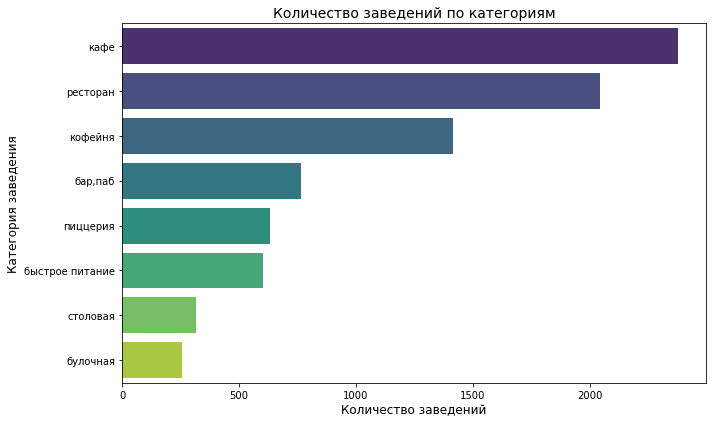

In [25]:
plt.figure(figsize=(10, 6))

sns.countplot(
    y='category',
    data=df,
    order=df['category'].value_counts().index,
    palette='viridis'
)

plt.title('Количество заведений по категориям', fontsize=14)
plt.xlabel('Количество заведений', fontsize=12)
plt.ylabel('Категория заведения', fontsize=12)

plt.tight_layout()
plt.show()

In [26]:
category_stats = pd.DataFrame({
    'Количество': df['category'].value_counts(),
    'Доля, %': (
        df['category'].value_counts(normalize=True) * 100
    ).round(1)
})

display(category_stats)

,Количество,"Доля, %"
кафе,2376,28.3
ресторан,2042,24.3
кофейня,1413,16.8
"бар,паб",764,9.1
пиццерия,633,7.5
быстрое питание,603,7.2
столовая,315,3.7
булочная,256,3.0


**Вывод:** Самой распространённой категорией заведений в Москве являются кафе — их доля составляет 28.3% от общего количества. На втором месте находятся рестораны (24.3%), а на третьем — кофейни (16.8%).

Меньше всего в Москве представлено булочных и столовых — их доли составляют 3% и 3.7% соответственно.

In [27]:
district_counts = df['district_short'].value_counts()

display(district_counts)

ЦАО     2242
САО      898
ЮАО      892
СВАО     890
ЗАО      850
ВАО      798
ЮВАО     714
ЮЗАО     709
СЗАО     409
Name: district_short, dtype: int64

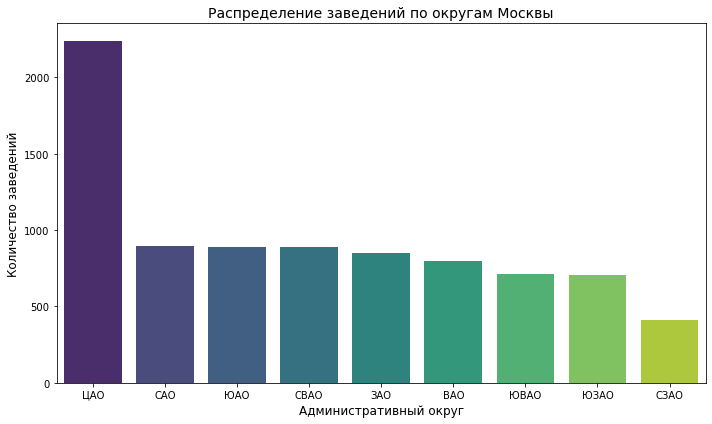

In [28]:
plt.figure(figsize=(10, 6))

sns.countplot(
    x='district_short',
    data=df,
    order=df['district_short'].value_counts().index,
    palette='viridis'
)

plt.title('Распределение заведений по округам Москвы', fontsize=14)
plt.xlabel('Административный округ', fontsize=12)
plt.ylabel('Количество заведений', fontsize=12)

plt.tight_layout()
plt.show()

**Вывод:** Больше всего заведений находится в ЦАО - 2242 заведения. Меньше всего в Cеверо-Западном округе, всего около 400 точек. 

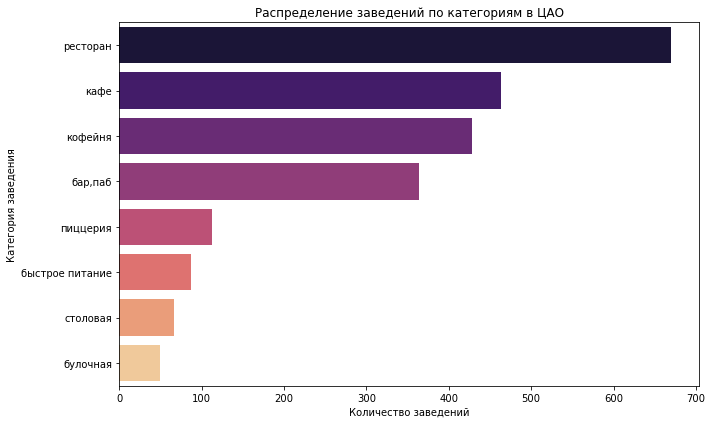

In [29]:
df_central = df[df['district_short'] == 'ЦАО'].copy()

plt.figure(figsize=(10, 6))

sns.countplot(
    y='category',
    data=df_central,
    order=df_central['category'].value_counts().index,
    palette='magma'
)

plt.title('Распределение заведений по категориям в ЦАО')
plt.xlabel('Количество заведений')
plt.ylabel('Категория заведения')

plt.tight_layout()
plt.show()

In [30]:
moscow_share = (
    df['category'].value_counts(normalize=True) * 100
)

central_share = (
    df_central['category'].value_counts(normalize=True) * 100
)

comparison = pd.DataFrame({
    'Москва, %': moscow_share,
    'ЦАО, %': central_share
}).fillna(0).round(1)

comparison['Разница'] = (
    comparison['ЦАО, %'] - comparison['Москва, %']
).round(1)

display(comparison)

,"Москва, %","ЦАО, %",Разница
"бар,паб",9.1,16.2,7.1
булочная,3.0,2.2,-0.8
быстрое питание,7.2,3.9,-3.3
кафе,28.3,20.7,-7.6
кофейня,16.8,19.1,2.3
пиццерия,7.5,5.0,-2.5
ресторан,24.3,29.9,5.6
столовая,3.7,2.9,-0.8


**Вывод:** В Центральном административном округе больше всего ресторанов, на втором месте находятся кафе, а на третьем — кофейни. 

При сравнении долей выяснилось, что рестораны составляют 24.3% всех заведений Москвы, а в ЦАО их доля достигает 29.9%. Разница составляет 5.6 п.п.

Таким образом, рестораны занимают большую долю среди заведений ЦАО, чем среди заведений Москвы в целом. Это показывает, что структура общественного питания в Центральном округе отличается от общегородской.

In [31]:
df['chain'].value_counts()

0    5199
1    3203
Name: chain, dtype: int64

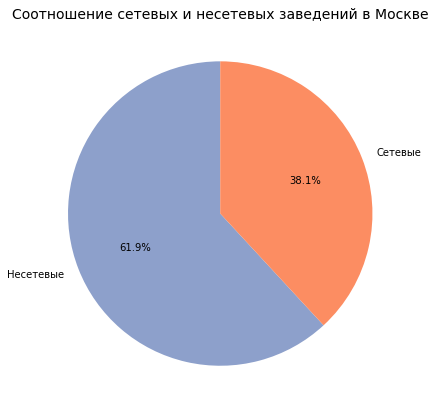

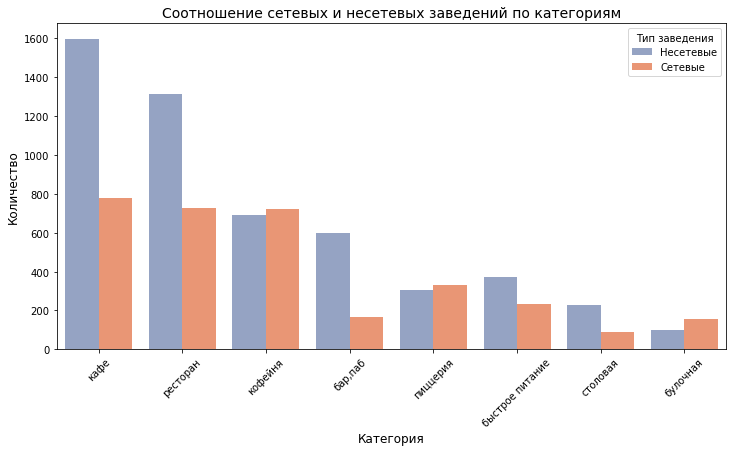

In [32]:
# Круговая диаграмма
plt.figure(figsize=(7, 7))
df['chain'].value_counts().plot(
    kind='pie', 
    autopct='%1.1f%%', 
    labels=['Несетевые', 'Сетевые'], 
    colors=['#8da0cb', '#fc8d62'],
    startangle=90
)
plt.title('Соотношение сетевых и несетевых заведений в Москве', fontsize=14)
plt.ylabel('')
plt.show()

# Соотношение в разрезе категорий
plt.figure(figsize=(12, 6))
sns.countplot(
    x='category', 
    hue='chain', 
    data=df, 
    order=df['category'].value_counts().index,
    palette=['#8da0cb', '#fc8d62']
)
plt.title('Соотношение сетевых и несетевых заведений по категориям', fontsize=14)
plt.xlabel('Категория', fontsize=12)
plt.ylabel('Количество', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Тип заведения', labels=['Несетевые', 'Сетевые'])
plt.show()

In [33]:
chain_shares = (df.groupby('category')['chain'].mean() * 100).sort_values(ascending=False)
print(chain_shares.round(1))

category
булочная           61.3
пиццерия           52.1
кофейня            51.0
быстрое питание    38.5
ресторан           35.7
кафе               32.8
столовая           27.9
бар,паб            22.0
Name: chain, dtype: float64


In [34]:
chain_counts = pd.crosstab(
    df['category'],
    df['chain']
)

chain_counts = chain_counts.reindex(
    columns=[0, 1], fill_value=0
)

chain_counts.columns = ['Несетевые', 'Сетевые']

chain_counts['Всего'] = (
    chain_counts['Несетевые'] + chain_counts['Сетевые']
)

chain_counts['Доля сетевых, %'] = (
    chain_counts['Сетевые'] /
    chain_counts['Всего'] * 100
).round(1)

display(
    chain_counts.sort_values(
        'Сетевые', ascending=False
    )
)

,Несетевые,Сетевые,Всего,"Доля сетевых, %"
category,,,,
кафе,1597,779,2376,32.8
ресторан,1313,729,2042,35.7
кофейня,693,720,1413,51.0
пиццерия,303,330,633,52.1
быстрое питание,371,232,603,38.5
"бар,паб",596,168,764,22.0
булочная,99,157,256,61.3
столовая,227,88,315,27.9


**Вывод:** В Москве преобладают несетевые заведения (около 62%). Самая высокая доля сетевых заведений у булочных (61,3%), пиццерий (52,1%) и кофеен (51%). Однако по количеству сетевых точек ситуация отличается.

Больше всего сетевых заведений среди кафе (779), ресторанов (729) и кофеен (720). При этом сетевых булочных всего 157, несмотря на их высокую долю внутри категории.

Особенно выделяются кофейни, у которых и доля сетевых заведений высокая, и их количество достаточно большое.

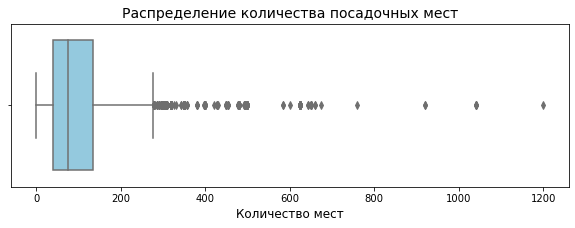

count    4781.000000
mean      105.647354
std       109.155834
min         0.000000
25%        40.000000
50%        75.000000
75%       135.000000
max      1200.000000
Name: seats, dtype: float64


In [35]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=df['seats'], color='skyblue')
plt.title('Распределение количества посадочных мест', fontsize=14)
plt.xlabel('Количество мест', fontsize=12)
plt.show()

print(df['seats'].describe())

In [36]:
df[df['seats'] > 300][
    ['name', 'category', 'seats', 'address']
].sort_values('seats', ascending=False).head(10)

,name,category,seats,address
4227,рестобар argomento,столовая,1200,"кутузовский проспект, 41, стр. 1"
2767,шоколадница,кофейня,1040,"измайловское шоссе, 71, корп. а"
2963,матрешка,кафе,1040,"измайловское шоссе, 71, корп. а"
2719,маргарита,быстрое питание,1040,"измайловское шоссе, 71, корп. а"
2710,ваня и гоги,"бар,паб",1040,"измайловское шоссе, 71, корп. а"
4176,eataly,"бар,паб",920,"киевская улица, 2"
4241,стейк & бургер,кафе,920,"киевская улица, 2"
5482,дом,кафе,760,"улица юности, 1"
7983,ресторан,ресторан,675,"улица маршала захарова, 6, корп. 1"
2910,хаус бар,"бар,паб",660,"измайловское шоссе, 71, корп. 2б"


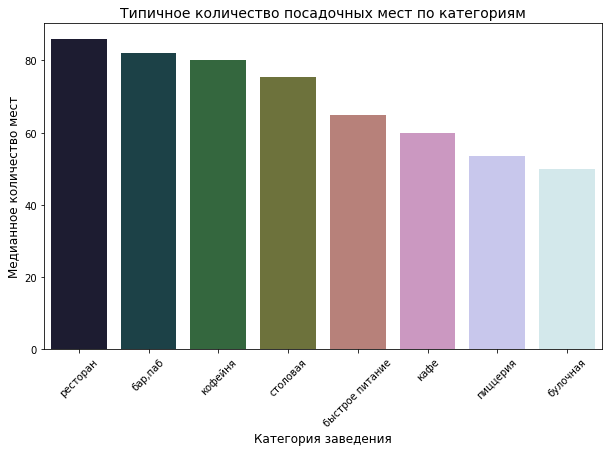

category
ресторан           86.0
бар,паб            82.0
кофейня            80.0
столовая           75.5
быстрое питание    65.0
кафе               60.0
пиццерия           53.5
булочная           50.0
Name: seats, dtype: Float64


In [37]:
med_seats = df.groupby('category')['seats'].median().sort_values(ascending=False)

# Строим график
plt.figure(figsize=(10, 6))
sns.barplot(
    x=med_seats.index, 
    y=med_seats.values, 
    palette='cubehelix'
)

plt.title('Типичное количество посадочных мест по категориям', fontsize=14)
plt.xlabel('Категория заведения', fontsize=12)
plt.ylabel('Медианное количество мест', fontsize=12)
plt.xticks(rotation=45)
plt.show()

print(med_seats)

**Вывод:** При проверке данных были обнаружены подозрительные значения количества посадочных мест, которые мы заменили на пропуски на этапе предобработки.

Для сравнения категорий использовали медиану, так как она меньше зависит от больших значений.

Самое большое медианное количество посадочных мест оказалось у ресторанов (86), баров и пабов (82), а также кофеен (80). Меньше всего мест у пиццерий (53,5) и булочных (50).

При этом стоит учитывать, что количество посадочных мест известно не для всех заведений, поэтому расчёты проводились только по заполненным значениям.

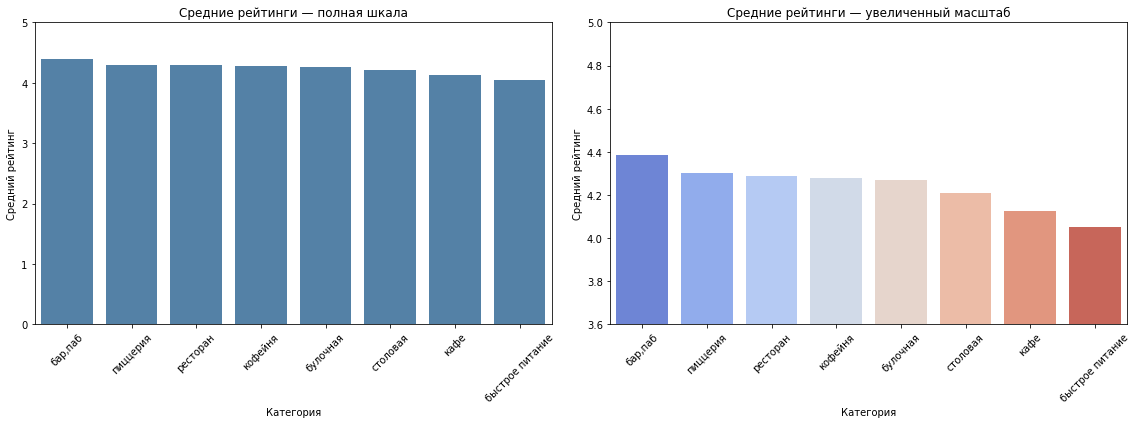

category
бар,паб            4.387696
пиццерия           4.301264
ресторан           4.290402
кофейня            4.277282
булочная           4.268359
столовая           4.211429
кафе               4.124285
быстрое питание    4.050249
Name: rating, dtype: float64


In [38]:
avg_rating = df.groupby('category')['rating'].mean().sort_values(ascending=False)

# Создаем два графика
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    x=avg_rating.index,
    y=avg_rating.values,
    color='steelblue',
    ax=axes[0]
)

axes[0].set_title('Средние рейтинги — полная шкала')
axes[0].set_xlabel('Категория')
axes[0].set_ylabel('Средний рейтинг')
axes[0].set_ylim(0, 5)
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(
    x=avg_rating.index,
    y=avg_rating.values,
    palette='coolwarm',
    ax=axes[1]
)

axes[1].set_title('Средние рейтинги — увеличенный масштаб')
axes[1].set_xlabel('Категория')
axes[1].set_ylabel('Средний рейтинг')
axes[1].set_ylim(3.6, 5)
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

print(avg_rating)

**Вывод:** Разброс средних рейтингов по категориям невелик (от 4.05 до 4.39). Наивысшие оценки получают бары и пабы, а самые низкие заведения быстрого питания.

interval columns not set, guessing: ['rating', 'chain', 'seats']


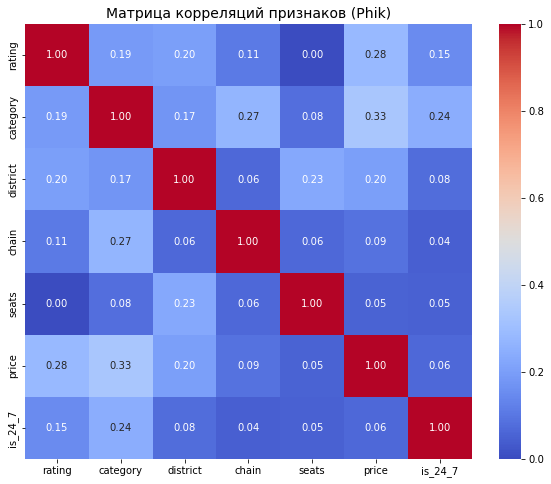

In [39]:
cols_for_corr = ['rating', 'category', 'district', 'chain', 'seats', 'price', 'is_24_7']

corr_matrix = df[cols_for_corr].phik_matrix()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=0, vmax=1)
plt.title('Матрица корреляций признаков (Phik)', fontsize=14)
plt.show()

In [40]:
print(
    'Доля неизвестных цен:',
    round(
        (df['price'] == 'Нет информации').mean() * 100,
        1
    ),
    '%'
)

Доля неизвестных цен: 60.5 %


In [41]:
price_category_shares = pd.crosstab(
    df['category'],
    df['price'],
    normalize='index'
) * 100

display(price_category_shares.round(1))

price,Нет информации,высокие,выше среднего,низкие,средние
category,,,,,
"бар,паб",35.3,15.8,20.0,0.3,28.5
булочная,84.0,2.3,1.6,1.2,10.9
быстрое питание,68.5,0.5,0.8,3.6,26.5
кафе,73.4,1.3,3.3,1.1,21.0
кофейня,66.3,1.2,1.0,4.8,26.7
пиццерия,50.9,4.7,6.3,0.6,37.4
ресторан,50.2,13.2,13.1,1.0,22.4
столовая,51.4,0.3,0.6,3.2,44.4


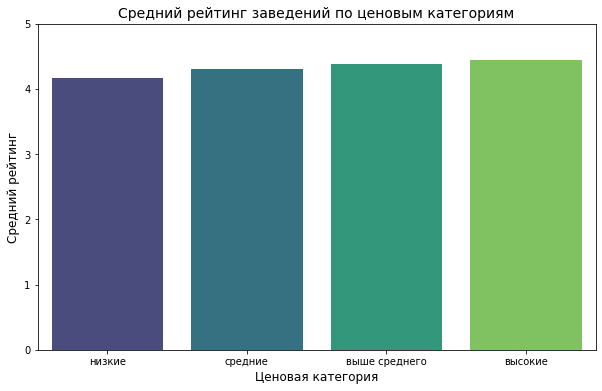

price
низкие           4.173077
средние          4.297874
выше среднего    4.386348
высокие          4.436611
Name: rating, dtype: float64


In [42]:
price_rating = (
    df[df['price'] != 'Нет информации']
    .groupby('price')['rating']
    .mean()
    .sort_values()
)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=price_rating.index, 
    y=price_rating.values, 
    palette='viridis'
)

plt.title('Средний рейтинг заведений по ценовым категориям', fontsize=14)
plt.xlabel('Ценовая категория', fontsize=12)
plt.ylabel('Средний рейтинг', fontsize=12)

plt.ylim(0, 5)
plt.show()

print(price_rating)

**Вывод:**  По матрице корреляций Phik заметна слабая связь между рейтингом и ценовой категорией (0.22). Дополнительно мы сравнили средние рейтинги по ценовым категориям и увидели, что дорогие заведения в среднем получают более высокие оценки (от 4.17 в дешевых до 4.44 в дорогих). 

Однако дополнительная проверка показала, что данные о ценах заполнены не полностью. У 60,5% заведений ценовая категория указана как «Нет информации».

Также выяснилось, что ценовые категории распределены неравномерно. Например, среди заведений с высокими ценами есть 270 ресторанов, но всего 3 заведения быстрого питания и 1 столовая.

Поэтому полученная связь между ценой и рейтингом может частично объясняться различиями между самими категориями заведений. Из-за большого количества неизвестных цен и неравномерного распределения данных нельзя сделать однозначный вывод о связи цены с рейтингом.

,places_count,avg_rating
name,,
шоколадница,120,4.177500
доминос пицца,76,4.169737
додо пицца,74,4.286486
one price coffee,71,4.064789
яндекс лавка,69,3.872464
cofix,65,4.075385
prime,50,4.116000
хинкальная,44,4.322727
кофепорт,42,4.147619


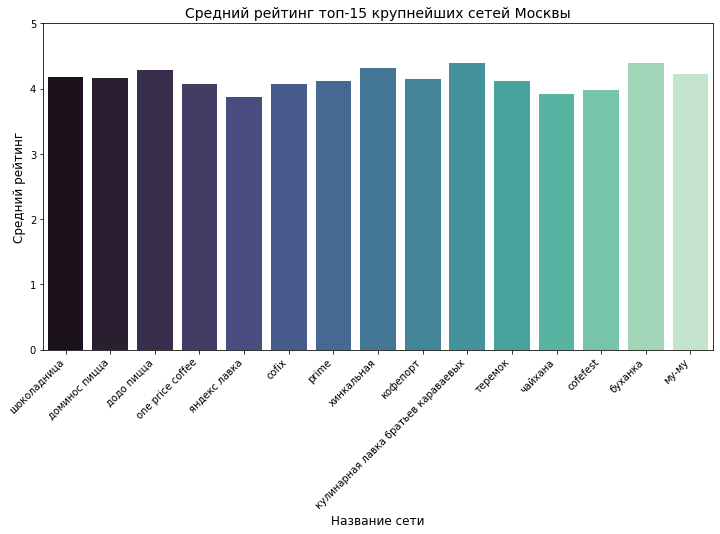

In [43]:
# Выбираем только сетевые заведения
chains = df[df['chain'] == 1]

# Находим топ-15 названий сетей по количеству заведений
top_15_names = chains['name'].value_counts().head(15).index

# Фильтруем датафрейм
top_15_data = chains[chains['name'].isin(top_15_names)]

# Группируем данные по названию сети, считаем количество заведений и средний рейтинг
top_15_stats = (
    top_15_data.groupby('name')
    .agg(
        places_count=('id', 'count'),
        avg_rating=('rating', 'mean')
    )
    .sort_values('places_count', ascending=False)
)

display(top_15_stats)

# Cтроим график
plt.figure(figsize=(12, 6))
sns.barplot(
    x=top_15_stats.index, 
    y=top_15_stats['avg_rating'], 
    palette='mako'
)

plt.title('Средний рейтинг топ-15 крупнейших сетей Москвы', fontsize=14)
plt.xlabel('Название сети', fontsize=12)
plt.ylabel('Средний рейтинг', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 5)
plt.show()

,places_count,avg_rating
category,,
булочная,25,4.416000
быстрое питание,12,4.341667
"бар,паб",4,4.325000
кафе,100,4.241000
пиццерия,151,4.227815
кофейня,336,4.115179
столовая,2,4.100000
ресторан,186,4.025806


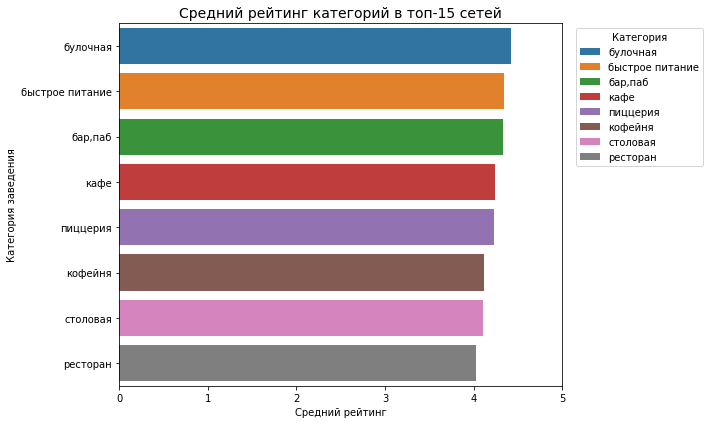

In [44]:
category_stats = (
    top_15_data.groupby('category')
    .agg(
        places_count=('id', 'count'),
        avg_rating=('rating', 'mean')
    )
    .sort_values('avg_rating', ascending=False)
)

display(category_stats)

# Подготавливаем таблицу для визуализации
category_plot = category_stats.reset_index()

# Строим график
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_plot,
    x='avg_rating',
    y='category',
    hue='category',
    palette='tab10',
    dodge=False
)

plt.title('Средний рейтинг категорий в топ-15 сетей', fontsize=14)
plt.xlabel('Средний рейтинг')
plt.ylabel('Категория заведения')
plt.xlim(0, 5)

plt.legend(title='Категория', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Вывод:** Среди 15 крупнейших сетей Москвы по количеству заведений лидирует «Шоколадница» — 120 точек. На втором месте находится «Доминос Пицца» (76 заведений), а на третьем — «Додо Пицца» (74 заведения).

Самые высокие средние рейтинги среди этих сетей у «Буханки» (4,40) и «Кулинарной лавки братьев Караваевых» (4,39). Самый низкий средний рейтинг у «Яндекс Лавки» (3,87).

Также мы сравнили рейтинги по категориям заведений, которые входят в топ-15 сетей. Самый высокий средний рейтинг оказался у булочных (4,42), а самый низкий — у ресторанов (4,03).

При этом количество заведений в категориях сильно отличается. Например, в выборке всего 25 булочных и 4 бара или паба, поэтому их средние рейтинги стоит оценивать с осторожностью.

Также в данных встречаются сети, заведения которых относятся к разным категориям. Возможные ошибки в определении категорий могут влиять на результаты сравнения.

In [45]:
bill_stats = df.groupby('district').agg(
    total=('id', 'count'),
    with_bill=('middle_avg_bill', 'count')
)

bill_stats['share'] = (
    bill_stats['with_bill'] /
    bill_stats['total'] * 100
).round(1)

display(bill_stats)

,total,with_bill,share
district,,,
Восточный административный округ,798,260,32.6
Западный административный округ,850,306,36.0
Северный административный округ,898,322,35.9
Северо-Восточный административный округ,890,301,33.8
Северо-Западный административный округ,409,157,38.4
Центральный административный округ,2242,1060,47.3
Юго-Восточный административный округ,714,194,27.2
Юго-Западный административный округ,709,235,33.1
Южный административный округ,892,314,35.2


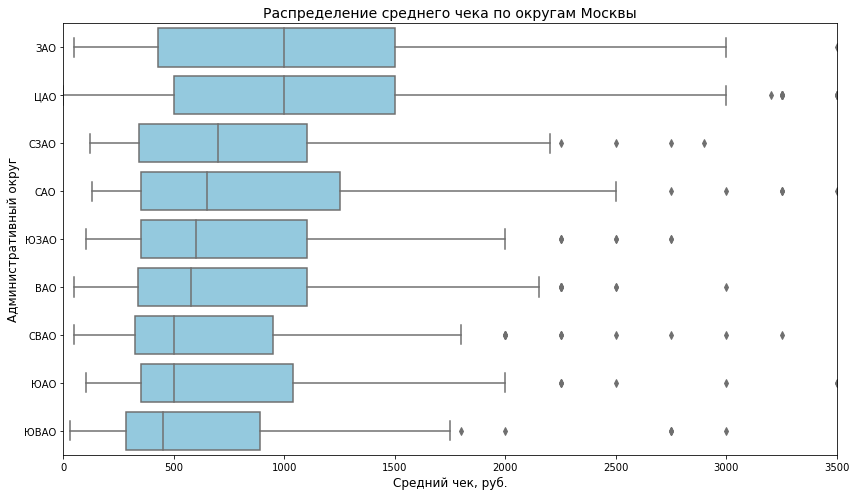

In [46]:
# Удаляем пустые значения чеков
df_bills = df.dropna(subset=['middle_avg_bill'])

# Сортируем округа по медианному чеку
district_order = (
    df_bills.groupby('district_short')['middle_avg_bill']
    .median()
    .sort_values(ascending=False)
    .index
)

# Строим горизонтальную диаграмму размаха
plt.figure(figsize=(12, 7))

sns.boxplot(
    x='middle_avg_bill',
    y='district_short',
    data=df_bills,
    order=district_order,
    color='skyblue'
)

plt.title('Распределение среднего чека по округам Москвы', fontsize=14)
plt.xlabel('Средний чек, руб.', fontsize=12)
plt.ylabel('Административный округ', fontsize=12)

plt.xlim(0, 3500)
plt.tight_layout()
plt.show()

In [47]:
# Выбираем рестораны с известным средним чеком
restaurant_bills = df_bills[
    df_bills['category'] == 'ресторан'
]

# Считаем количество ресторанов и медианный чек по округам
restaurant_stats = (
    restaurant_bills.groupby('district_short')
    .agg(
        places_count=('id', 'count'),
        median_bill=('middle_avg_bill', 'median')
    )
    .sort_values('median_bill', ascending=False)
)

display(restaurant_stats)

,places_count,median_bill
district_short,,
ЗАО,116,1300.0
СЗАО,48,1250.0
ЦАО,406,1250.0
САО,96,1187.5
ЮЗАО,78,1050.0
ВАО,68,1000.0
ЮАО,90,975.0
ЮВАО,54,925.0
СВАО,84,837.5


In [48]:
# Доля ресторанов среди всех заведений округа
restaurant_share_all = (
    df.assign(is_restaurant=df['category'] == 'ресторан')
    .groupby('district_short')['is_restaurant']
    .mean() * 100
)

# Доля ресторанов среди заведений с известным чеком
restaurant_share_bills = (
    df_bills.assign(is_restaurant=df_bills['category'] == 'ресторан')
    .groupby('district_short')['is_restaurant']
    .mean() * 100
)

# Сравниваем состав полной выборки и выборки с чеками
restaurant_comparison = pd.DataFrame({
    'Рестораны среди всех, %': restaurant_share_all,
    'Рестораны среди известных чеков, %': restaurant_share_bills
}).round(1)

restaurant_comparison['Разница, п.п.'] = (
    restaurant_comparison['Рестораны среди известных чеков, %'] -
    restaurant_comparison['Рестораны среди всех, %']
).round(1)

display(
    restaurant_comparison.sort_values(
        'Разница, п.п.', ascending=False
    )
)

,"Рестораны среди всех, %","Рестораны среди известных чеков, %","Разница, п.п."
district_short,,,
ЗАО,25.6,37.9,12.3
ЮЗАО,23.7,33.2,9.5
САО,20.9,29.8,8.9
ЦАО,29.9,38.3,8.4
СВАО,20.4,27.9,7.5
ЮВАО,20.3,27.8,7.5
ВАО,20.1,26.2,6.1
ЮАО,22.6,28.7,6.1
СЗАО,26.7,30.6,3.9


**Вывод:** При сравнении всех заведений по округам выяснилось, что самый высокий медианный чек в ЦАО и ЗАО — 1000 рублей. Самый низкий медианный чек оказался в ЮВАО — 450 рублей.

Чтобы проверить, связаны ли различия в ценах с категориями заведений, мы отдельно сравнили медианный чек ресторанов по округам.

Среди ресторанов самый высокий медианный чек оказался в ЗАО (1300 рублей), а самый низкий — в СВАО (837,5 рубля). В ЦАО медианный чек ресторанов составляет 1250 рублей, а в ЮВАО — 925 рублей.

Таким образом, различия в ценах сохраняются даже при сравнении заведений одной категории. При этом нельзя утверждать, что чек всегда снижается по мере удаления от центра. Например, в СЗАО медианный чек ресторанов такой же, как в ЦАО — 1250 рублей.

Также стоит учитывать, что информация о среднем чеке есть не для всех заведений. Поэтому результаты основаны только на тех заведениях, для которых эти данные известны.

**Дополнительная проверка полноты данных:** При сравнении структуры всех заведений и заведений с известным средним чеком обнаружили, что рестораны сильнее представлены во второй группе.

Наибольшая разница наблюдается в ЗАО: доля ресторанов увеличивается с 25,6% до 37,9% (на 12,3 п.п.). В ЮЗАО разница составляет 9,5 п.п., в ЦАО — 8,4 п.п., а в СЗАО — 3,9 п.п.

Это говорит о том, что заведения с известным средним чеком могут не полностью отражать структуру рынка каждого округа. Поэтому результаты сравнения медианных чеков следует интерпретировать с осторожностью: на них может влиять не только расположение заведения, но и состав доступных данных.

## Шаг 4. Итоговый вывод и рекомендации

#### 1. Общий обзор проделанной работы
В ходе проекта мы изучили рынок заведений общественного питания Москвы. Для анализа использовали датасет, в котором содержится информация о более чем 8 тысячах заведений.

Сначала мы подготовили данные к анализу: проверили пропуски, удалили 4 неявных дубликата и исправили типы данных. Также добавили новый столбец is_24_7, с помощью которого выяснили, что в Москве есть 730 круглосуточных заведений. Некоторые пропуски оставили, так как их нельзя было корректно заполнить.

После предобработки мы провели исследовательский анализ данных. Посмотрели, какие категории заведений встречаются чаще всего, как они распределены по округам Москвы, сколько среди них сетевых и несетевых заведений. Также изучили количество посадочных мест, средний чек и рейтинги заведений.

#### 2. Главные выводы исследования
1. **Категории заведений.** Больше всего в Москве кафе. При этом в Центральном административном округе (ЦАО) чаще встречаются рестораны. Меньше всего в датасете булочных.
2. **Расположение и средний чек.** Больше всего заведений находится в ЦАО. Также выяснилось, что в ЦАО и ЗАО самый высокий медианный чек - около 1000 рублей. В южных и юго-восточных районах цены ниже: в ЮАО и ЮВАО медианный чек составляет примерно 450–500 рублей.
3. **Сетевые и несетевые заведения.** Большая часть заведений Москвы (62%) не относится к сетям. При этом булочные, пиццерии и кофейни чаще других категорий работают в сетевом формате. Самой крупной сетью в датасете оказалась «Шоколадница» - 120 заведений.
4. **Количество посадочных мест.** В ходе исследования были обнаружены подозрительные значения — 1288 посадочных мест у нескольких разных заведений на проспекте Вернадского. Их посчитали возможной ошибкой и заменили на пропуски, сохранив остальные данные о заведениях.
После обработки выяснилось, что самое большое медианное количество посадочных мест у ресторанов (86), баров и пабов (82) и кофеен (80). Меньше всего мест оказалось у булочных (50).
5. **Рейтинги заведений.** Средние рейтинги по категориям находятся в диапазоне от 4.05 до 4.39. Самые высокие оценки у баров и пабов, а самые низкие у заведений быстрого питания.
Анализ Phik показал слабую связь между рейтингом и ценовой категорией (0.22). При сравнении средних рейтингов выяснилось, что дорогие заведения в среднем получают более высокие оценки — 4.44 против 4.17 у бюджетных. Однако это не означает, что высокая цена сама по себе приводит к более высокому рейтингу.

#### 3. Рекомендации для заказчика
1. **Выбор категории и расположения.** Если планируется открытие заведения в ЦАО, можно рассмотреть открытие ресторана, так как это самая распространённая категория в ЦАО.
2. **Работа с высоким чеком:** ЗАО также можно рассмотреть для открытия заведения с высоким средним чеком, поскольку медианный чек в этом округе составляет 1000 рублей, как и в ЦАО.
3. **Открытие сети заведений.** Если инвестор планирует развивать сеть, можно обратить внимание на кофейни и пиццерии, где доля сетевых заведений превышает 50%. Особенно выделяются кофейни: в Москве насчитывается 720 сетевых кофеен.
У булочных доля сетевых заведений ещё выше — 61,3%, однако их абсолютное количество значительно меньше — 157 точек. Поэтому для выбора формата сети необходимо дополнительно оценить спрос и конкуренцию.
4. **Выбор ценового сегмента.** В ЮАО и ЮВАО медианный чек среди заведений с известными ценами составляет около 450–500 рублей, что ниже показателей ЦАО и ЗАО. Поэтому при открытии заведения в этих округах можно дополнительно изучить перспективы формата с невысоким или средним чеком. Для окончательного решения потребуется оценить спрос, конкурентов и особенности конкретной локации.
5. **Количество посадочных мест.** При выборе помещения можно ориентироваться на медианное количество мест у заведений той же категории. Например, для ресторана можно рассмотреть помещение на 80–90 мест, для кофейни — около 80 мест, а для булочной — около 50 мест. При этом окончательное количество мест будет зависеть от формата заведения, площади помещения и бюджета.